# 2.1 LabOrch Tutorial

This tutorial assumes that the laborch packages have been installed and the installation tests pass.

In [1]:
import sys
sys.path.insert(0, '..')   # or: pip install -e ..

import numpy as np
import matplotlib.pyplot as plt
from laborch import Bank, nnls_fit, pinv_fit, dot, INSTRUMENT_NAMES
from laborch.bank import frequencies

## The Bank

To get started, we load the bank instruments.  
Currently the Bank is stored as 1,515 text files.   
The next project phase_1 is to build a more efficient Bank format with the ability to add new sound libraries to the Bank.

First we *load* the 1,515 files, reading the text files from disk (in `FFT_DIR`), then cache them in a numpy container file on disk for fast retrieval, `../.cache/fftbank.npz`.

In [2]:
bank = Bank.load()

`bank` is now an array of all available FFT spectra.

In [3]:
print(len(bank), 'sounds,', len(bank.instruments), 'instruments')

1515 sounds, 33 instruments


A more complete description of the **Bank** can be gotten from the attribute`bank.info` which returns a dictionary of `SoundName` objects. 

In [4]:
#bank.info

`bank.instruments` is a list of the 3-letter codes of instruments in the bank filenames.

Here are the first 10 `bank.instruments`:

In [5]:
bank.instruments[:10]

['afl', 'alx', 'bcl', 'bfl', 'brx', 'bsn', 'bsx', 'btb', 'cbc', 'cbs']

`INSTRUMENT_NAMES` is a dictionary that translates these 3-letter codes to full names.

The `bank` contains the following instruments.

In [6]:
for i in bank.instruments:
      print(i, ':', INSTRUMENT_NAMES[i])

afl : Alto Flute
alx : Alto Sax
bcl : Bass Clarinet
bfl : Bass Flute
brx : Baritone Sax
bsn : Bassoon
bsx : Bass Saxophone
btb : Bass Trombone
cbc : Contra Bass Clarinet
cbs : Contra Bassoon
clb : Bb Clarinet
cle : Eb Clarinet
cro : Crotales
ctb : Contrabass
enh : English Horn
flu : Flute
frh : French Horn
glk : Glockenspiel
mrb : Marimba
obo : Oboe
pic : Piccolo
pno : Piano
spx : Soprano Sax
tba : Tuba
tbb : Tubular Bells
tnx : Tenor Sax
tpc : C Trumpet
trb : Tenor Trombone
vib : Vibraphone
vla : Viola
vlc : Cello
vln : Violin
xyl : Xylophone


---

## The Target, Ensemble, and Palette

## Target.

Here we will use a **Target** that is already in the **Bank**.

Later we will be able to use uploaded sounds.

Below, the **Target** file is defined by the `laborch` filename conventions. 

In [7]:
target_name = 'clb-a3-ord-mf'

In [8]:
bank.instruments[:8]

['afl', 'alx', 'bcl', 'bfl', 'brx', 'bsn', 'bsx', 'btb']

## Ensemble

The **Ensemble** is the set of instrument for which you are composing. In this case, a string trio: Violin, Viola, and Cello.

We select the **Ensemble** using the instrument 3-letter acronyms.

In [9]:
ensemble = ['vln', 'vla', 'vlc']

The *dictionary* `INSTRUMENT_NAMES[]` converts 3-letter acronymns to full names.

In [10]:
[INSTRUMENT_NAMES[i] for i in ensemble]

['Violin', 'Viola', 'Cello']

## Palette

Next we define the **Palette** as the spectra of the sounds that the **Ensemble** can perform.

`bank.select()` creates a subset of the full **Bank**.

In [11]:
palette = bank.select(instruments=ensemble, exclude=[target_name])

In [12]:
type(palette)

laborch.bank.Palette

The total number of sounds in the **Palette** is:

In [13]:
len(palette)

327

---

## Projecting the Target onto Palette

The projection of the Target onto the Palette is in frequency space, so we need the FFT spectrum of the target sound.   

If the sound is already in the **Bank**, the method:   
`bank.spectrum()`   
gets the spectrum of that sound from a string specifying the sound in . This string specifies the sound in `SoundName()` format:

<pre>
'afl-a5-ord-mf' = SoundName(instrument='afl', note='a', octave=5, mode='ord', dynamic='mf', string=None, variant=''),
</pre>

This is the format we used above for our trombone note `target_name`.

In [14]:
target_name

'clb-a3-ord-mf'

Let's get the spectrum of the **Target**. We'll save this in the variable `target_fft` 

In [15]:
target_fft = bank.spectrum(target_name)

`target_fft` is an array of the spectrum of the target at 2048 frequencies 

In [16]:
target_fft

array([0.011, 0.005, 0.001, ..., 0.   , 0.   , 0.   ])

In [17]:
len(target_fft)

2048

---

### SVD

Let's reproduce one of the algorithms of Rose & Hetrick 2009: *SVD* (pseudo-inverse by singular value decomposition).

`pinv_fit()` returns a `fit` object that has the names and coefficients of the projection.

In [18]:
p = pinv_fit(palette, target_fft)

In [19]:
type(p)

laborch.solve.Fit

The `Fit` object contains the information about the projection, including the weights for each **Palette** instrument sound, as well as info about the quality of the fit, such as the $\displaystyle{\chi^2}$ and the relative error between the **Target** spectrum and the weighted sum of all **Palette* sounds

In [20]:
p.chi2, p.relative_error

(0.00010493510813470674, 0.04976222253576027)

In [21]:
p.weights

array([ 0.045, -0.015,  0.005, -0.131, -0.076, -0.009,  0.129, -0.072,
        0.06 , -0.096,  0.001,  0.096, -0.327,  0.201,  0.215,  0.04 ,
       -0.022,  0.174, -0.074,  0.001,  0.207,  0.151,  0.03 ,  0.002,
        0.021, -0.011,  0.001, -0.117,  0.184, -0.005,  0.01 ,  0.035,
       -0.017,  0.017, -0.058,  0.012, -0.038,  0.167, -0.022,  0.016,
       -0.057, -0.036,  0.004,  0.071, -0.371, -0.001, -0.089, -0.216,
        0.29 ,  0.002,  0.028, -0.013, -0.101,  0.041,  0.05 , -0.022,
        0.095, -0.045,  0.083,  0.007,  0.027,  0.001,  0.   , -0.054,
       -0.155, -0.045, -0.072,  0.086,  0.017,  0.023,  0.049, -0.166,
        0.059, -0.008, -0.001,  0.005, -0.019,  0.013, -0.046,  0.013,
        0.02 , -0.035,  0.006, -0.003,  0.   , -0.017, -0.034, -0.005,
       -0.026,  0.011, -0.025,  0.002,  0.071, -0.082, -0.025,  0.088,
       -0.031,  0.028, -0.056,  0.175,  0.034, -0.011, -0.001,  0.046,
       -0.008, -0.003, -0.017,  0.134, -0.116, -0.131, -0.078, -0.039,
      

Notice that the number of weights matches the total number of **Palette** sounds.

In [22]:
len(palette), len(p.weights)

(327, 327)

We can get a summary of the first few weights and sounds with `.summary(n)`

In [23]:
print(p.summary(10))

pinv: 327 sounds, relative error 0.050
    0.9269  vln-a3-ord-mf
    0.8410  vlc-cs2-mtd-mf
    0.7894  vlc-a3o-mtd-mf
    0.6180  vlc-b2-ord-mf
    0.5224  vlc-g2o-mtd-mf
    0.4914  vlc-3g3-nhr-mf
    0.4400  vlc-ds3-ord-mf
    0.4214  vln-cs4-mtd-mf
    0.4078  vlc-as2-mtd-mf
    0.3853  vlc-ds2-ord-mf


All weights

<BarContainer object of 327 artists>

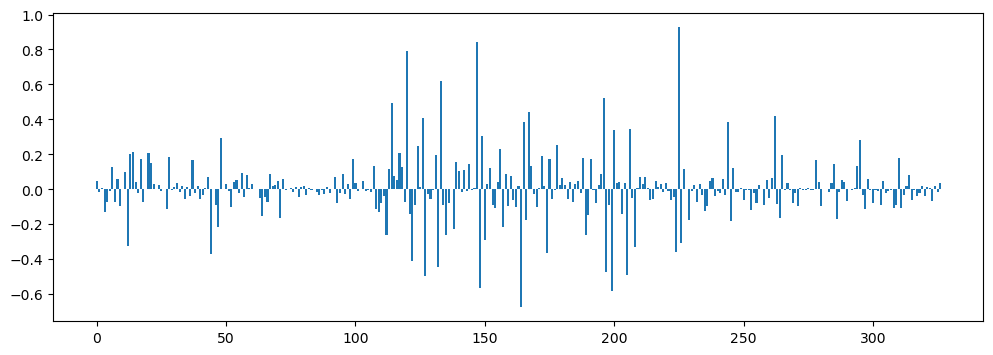

In [24]:
plt.figure(figsize=(12,4))
plt.bar(range(len(palette)), p.weights)

An issue with this projection is that some weights can be negative. Many in fact.

In [25]:
print('positive pinv weights:', (p.weights > 0).sum())

positive pinv weights: 159


In [26]:
print('negative pinv weights:', (p.weights < 0).sum())

negative pinv weights: 168


It's not clear how to interpret these negative weights.

While these values may be of use to the composer, a better projection is one that provides only non-negative weights.

### Non-negative Least Squares Fit: $~$ `nnls_fit()`

In [27]:
fit = nnls_fit(palette, target_fft)

In [28]:
fit.weights

array([0.   , 0.015, 0.   , 0.   , 0.043, 0.   , 0.   , 0.   , 0.   ,
       0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.   , 0.   , 0.033, 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.004, 0.   ,
       0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.   , 0.   , 0.   , 0.062, 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.   , 0.   , 0.   , 0.052, 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.012, 0.   , 0.   , 0.126, 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.109,
       0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.   , 0.   , 0.   , 0.323, 0.24 , 0.   , 0.   , 0.   , 0.   ,
       0.   , 0.   ,

NNLS fits are much more sparse.

<BarContainer object of 327 artists>

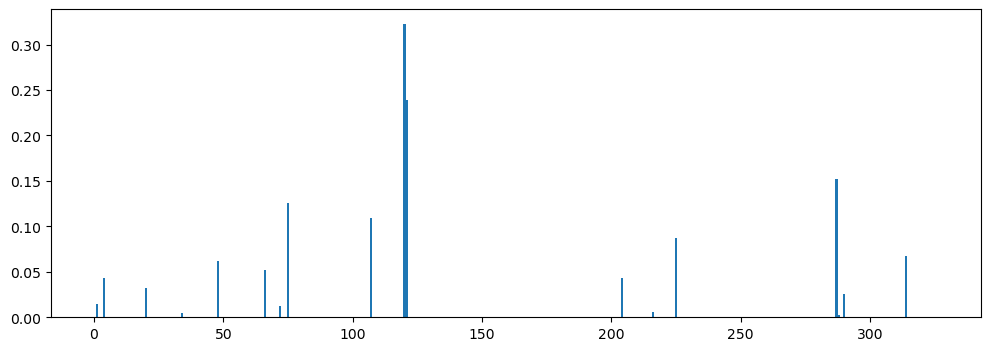

In [29]:
plt.figure(figsize=(12,4))
plt.bar(range(len(palette)), fit.weights)

In [30]:
print(fit.summary(10))

nnls: 327 sounds, relative error 0.323
    0.3227  vlc-a3o-mtd-mf
    0.2396  vlc-a3o-ord-mf
    0.1525  vln-e5o-mtd-mf
    0.1262  vla-e5-mtd-mf
    0.1088  vlc-1cs6-nhr-mf
    0.0867  vln-a3-ord-mf
    0.0670  vln-g6-mtd-mf
    0.0624  vla-cs5-ahr-mf
    0.0518  vla-ds4-ord-mf
    0.0427  vlc-g5-ord-mf


## Keep the top N sounds

`top(n)` keeps the weights as they were originally produced by projecting the **Target** onto *all* **Palette** sounds (the 2020 behaviour);   

`refit=True` re-solves on just the palette made of the N kept sounds, adjusting their weights.

To see how much the weights change in this process, we print the weights for the top 1, 3, and 8 sounds.  

In [31]:
for n in (1, 3, 8):
    t, r = fit.top(n), fit.top(n, refit=True);
    print('----------')
    print(t.summary)
    print()
    print(f'N={n} kept share {fit.kept_fraction(n):.2f}, rel. error = {t.relative_error:.3f} -> after refit {r.relative_error:.3f}')

----------
<bound method Fit.summary of Fit(names=['vlc-a3o-mtd-mf'], weights=array([0.323]), target=array([0.011, 0.005, 0.001, ..., 0.   , 0.   , 0.   ]), method='nnls/top1')>

N=1 kept share 0.23, rel. error = 0.634 -> after refit 0.499
----------
<bound method Fit.summary of Fit(names=['vlc-a3o-mtd-mf', 'vlc-a3o-ord-mf', 'vln-e5o-mtd-mf'], weights=array([0.323, 0.24 , 0.153]), target=array([0.011, 0.005, 0.001, ..., 0.   , 0.   , 0.   ]), method='nnls/top3')>

N=3 kept share 0.51, rel. error = 0.453 -> after refit 0.419
----------
<bound method Fit.summary of Fit(names=['vlc-a3o-mtd-mf', 'vlc-a3o-ord-mf', 'vln-e5o-mtd-mf', 'vla-e5-mtd-mf', 'vlc-1cs6-nhr-mf', 'vln-a3-ord-mf', 'vln-g6-mtd-mf', 'vla-cs5-ahr-mf'], weights=array([0.323, 0.24 , 0.153, 0.126, 0.109, 0.087, 0.067, 0.062]), target=array([0.011, 0.005, 0.001, ..., 0.   , 0.   , 0.   ]), method='nnls/top8')>

N=8 kept share 0.83, rel. error = 0.340 -> after refit 0.334


---

### Visualizing spectra

The FFT spectra are stored as an array of power values, at 2048 frequencies.

The utility function `frequencies()` returns the centre frequency (Hz) of each spectrum bin, with bin 0 = the constant term, $w_0$.

After the zero-frequency term, the lowest frequency in the spectrum (and the freqency step size) is 10.77 Hz. The highest is 22,039 Hz.

In [32]:
f = frequencies()
f

array([    0.   ,    10.767,    21.533, ..., 22017.7  , 22028.467,
       22039.233])

Let's get the top 3 notes in our projection

In [33]:
r = fit.top(3, refit=True)

print(r.summary())

nnls: 3 sounds, relative error 0.419
    0.3480  vlc-a3o-mtd-mf
    0.3295  vln-e5o-mtd-mf
    0.2645  vlc-a3o-ord-mf


Notice that the viola has two notes in the top 3, and the cello none. Since we want one note-per-instrument, we need to look at more of highest weights.

In [34]:
r = fit.top(4, refit=True)

print(r.summary())

nnls: 4 sounds, relative error 0.409
    0.3160  vlc-a3o-mtd-mf
    0.3041  vlc-a3o-ord-mf
    0.2216  vln-e5o-mtd-mf
    0.1457  vla-e5-mtd-mf


In [35]:
r = fit.top(5)

print(r.summary())

nnls/top5: 5 sounds, relative error 0.371
    0.3227  vlc-a3o-mtd-mf
    0.2396  vlc-a3o-ord-mf
    0.1525  vln-e5o-mtd-mf
    0.1262  vla-e5-mtd-mf
    0.1088  vlc-1cs6-nhr-mf


### Recommendation

Let's get "the one best" sound (note) for each ensemble instrument.

This will be incorporated into a *recommendation* function soon.

In [36]:
from laborch import Palette

best = {}
for name, w in fit.ranked():
    best.setdefault(bank.info[name].instrument, name)
pal1 = Palette(list(best.values()),
                 np.column_stack([bank.spectrum(n) for n in best.values()]))
bfit = nnls_fit(pal1, target_fft)
print(bfit.summary())

nnls: 3 sounds, relative error 0.425
    0.5535  vlc-a3o-mtd-mf
    0.2192  vln-e5o-mtd-mf
    0.1152  vla-e5-mtd-mf


## Plot spectra with `plt`

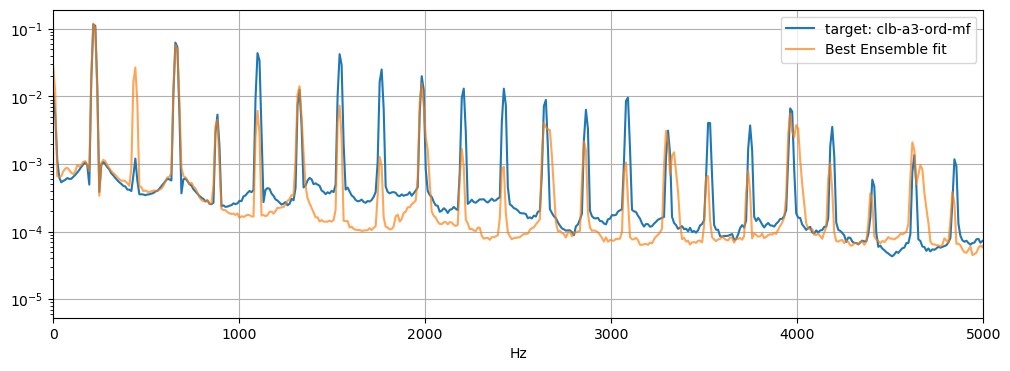

In [37]:
plt.figure(figsize=(12, 4))
plt.semilogy(f, target_fft, label='target: ' + target_name)
plt.semilogy(f, bfit.model, label='Best Ensemble fit', alpha=0.7)
plt.xlim(0, 5000); plt.xlabel('Hz'); plt.legend(); plt.grid()

---

## Listen
Needs **pydub + ffmpeg**. Installation instructions needed.

In [38]:
from laborch.audio import load_segment

### Target

In [39]:
target_name

'clb-a3-ord-mf'

### Use: Audio recodings for Target and Ensemble mix

Below, we read the audio recordings from disk, mix, and play.

#### Target audio

In [40]:
load_segment(bank.sound_path(target_name))

#### Mix audio

In [41]:
from laborch.audio import render_fit
from laborch.spectra import load_segment
mix = render_fit(bank, bfit.top(3, refit=True), n=3)
mix

---

### Synthesized sounds

In [42]:
from laborch.synth import spectrum_to_audio
from IPython.display import Audio

#### Recommendation mix FFT -> Audio

**Target** synthesized from Target FFT spectrum.

In [43]:
Audio(spectrum_to_audio(target_fft, seconds=2), rate=44100)

**Ensemble Mix** synthesized from Ensemble Recommendation FFT mixture.

In [44]:
Audio(spectrum_to_audio(bfit.model, seconds=2), rate=44100,)